# H3 — 差距是否局部化（升班马 / 早轮次）

逐场 gap = ℓ_B4 − ℓ_B6，对 promoted / early(matchday≤6) + 联赛×赛季固定效应做 OLS，系数区间用 48 块簇 bootstrap。

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
%matplotlib inline


In [2]:
from src.eval.localisation import build_h3_frame, h3_coefficients, h3_sweep
from src.eval.decisions import h3_verdict

df = build_h3_frame()
print('配对场数:', len(df))
r = h3_coefficients(df, w=6, B=10_000, seed=20261110)
print('promoted:', r['promoted'])
print('early   :', r['early'])
v = h3_verdict(r['promoted']['coef'], r['promoted']['lo'], r['promoted']['hi'],
               r['early']['coef'], r['early']['lo'], r['early']['hi'])
print('H3:', v['decision'], '—', v['reason'])

配对场数: 16728


promoted: {'coef': 0.011107533310899576, 'lo': -0.00013873300212842392, 'hi': 0.023697189871364273}
early   : {'coef': -0.010758214543256185, 'lo': -0.017579927528524206, 'hi': -0.004138960872238212}
H3: 只作描述 — 至少一个系数跨 0，不宣称成立或证伪


In [3]:
sw = h3_sweep(df)
print(sw.round(4).to_string(index=False))

 window    coef      lo      hi
      3 -0.0117 -0.0206 -0.0028
      6 -0.0108 -0.0176 -0.0041
     10 -0.0095 -0.0157 -0.0033


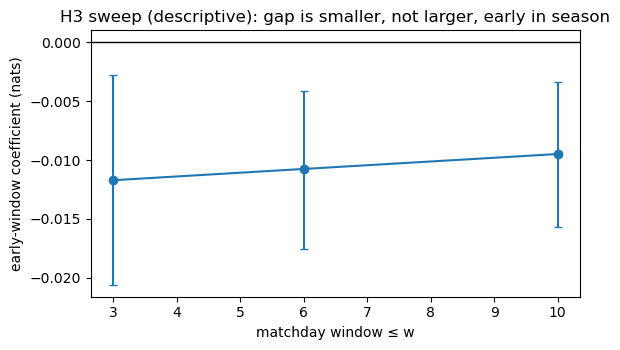

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6,3.6))
ax.errorbar(sw['window'], sw['coef'], yerr=[sw['coef']-sw['lo'], sw['hi']-sw['coef']],
            fmt='o-', capsize=3)
ax.axhline(0, color='k', lw=1)
ax.set_xlabel('matchday window ≤ w'); ax.set_ylabel('early-window coefficient (nats)')
ax.set_title('H3 sweep (descriptive): gap is smaller, not larger, early in season')
fig.tight_layout(); plt.show()

**结论**：promoted 系数为正但区间下界 −0.0001（跨 0）；early 系数为**负**（−0.0108，90% CI 全在 0 以下），与「早轮次差距更大」的假设方向相反。按预注册规则，两系数未同时满足「正且下界 > 0」⇒ **只作描述，不宣称成立或证伪**。